<h1>K-means</h1>
<h3>Octavio Vieyra Orozco</h3>
<p>ovieyra003@uvaq.edu.mx<p>

In [1]:
# Importar librerias de apoyo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar el dataset
colegios = pd.read_excel("/Users/octaviovieyra/Downloads/Kn_Vision_by_Colegios.xlsx")
estudiantes = pd.read_csv("/Users/octaviovieyra/Downloads/estudiantes_kmeans.csv")

In [3]:
# el head de los datasets
print("Head del dataset de colegios:")
print(colegios.head())
print("\nHead del dataset de estudiantes:")
print(estudiantes.head())

Head del dataset de colegios:
                                            Colegio      Kn Code  Val MOVS  \
0            Colegio Salesiano Don Bosco de Sahuayo  MX-MIC-0434         0   
1  Colegio Inglés Durkheim (Plantel Kínder Polanco)  MX-CMX-0467         0   
2                                  Instituto México  MX-SLP-0460         0   
3             Colegio Guadalupe de Guadalajara A.C.  MX-JAL-0424         0   
4   Colegio Bilingüe "Petit Academy" de Green Hills  MX-COA-0412         0   

   Val MAT  Val CRP  Val SOL  Val M/U  Total Val  Segmento  
0       -1        1        4      2.0       2.10         2  
1        1        1        1      2.9       1.76         2  
2       -1        1        4      2.3       2.22         2  
3       -1        1        4      3.6       2.74         3  
4       -1        1        4      2.6       2.34         3  

Head del dataset de estudiantes:
   promedio  materias_reprobadas  carga_academica  asistencia  horas_estudio  \
0      78.6          

In [4]:
# Importar el algoritmo de K-means
from sklearn.cluster import KMeans
# Importar la función de estandarización
from sklearn.preprocessing import StandardScaler
"""
Importamos PCA, una técnica de reducción de dimensionalidad que permite 
representar datos con muchas variables en un espacio menor dimensión, en 
este caso se va a usar para visualizar ls clústeres en un plano bidimensional.
"""
from sklearn.decomposition import PCA
# Importar la función de división de datos
from sklearn.model_selection import train_test_split
#Importar metricas de evaluación
from sklearn.metrics import silhouette_score

In [5]:
"""
Estadarizamos todas las variables del conjunto de datos. Primero, StandarScaler() crea un objeto
encargado de realizar la estandarización.

El método fit() calcula la media y la desviación estándar de cada variable del conjunto de datos.

Posteriormente, transform() utiliza esos valores para convertir cada variable a una nueva escala 
con media 0 y desviación estándar 1. 
Esto es importante para que todas las variables tengan la misma importancia en el análisis de clústeres.

La instrucción fit_transform() realiza ambos pasos en una sola línea, devolviendo un nuevo conjunto de 
datos estandarizado que almacenamos en una variable. Este paso es fundamental en K-means, ya que el 
algoritmo agrupa las observaciones utilizando distancias y , si las varibles tienen escalas muy diferentes,
aquellas con valores más grandes tedran una mayor afluencia en la formación de los clústeres.
"""
# Instaciamos el objeto StandardScaler
scaler = StandardScaler()
# Estandarizamos los datos de los estudiantes
estudiantes_scaled = scaler.fit_transform(estudiantes)

# Selecionamos las columnas que queremos estandarizar del dataset de colegios
colegios_km = colegios[['Val MOVS', 'Val MAT', 'Val CRP', 'Val SOL', 'Val M/U']]
colegios_scaled = scaler.fit_transform(colegios_km)

In [6]:
# Creamos una lista vacía para almacenar la inercia obtenida con cada valor de k
# La inercia mide qué tan compactos son los clústeres.
# Mientras menos sea este valor, más cercanos estarán de los datos a sus centroides
inercias_estudiantes = []
inercias_colegios = []

In [7]:
"""
Importante: Este bloque sólo se debe de ejecutar una vez para evitar el sobre dimencionamiento de la lista

Probamos diferentes cantidades de clústeres, desde K=1 hasta K=10.
El objetivo es encontrar el número de clústeres que mejor representa la estractura de los datos mediante
el método del codo (Elbow Method). 
"""

for k in range(1, 11):
    # Creamos un modelo K-Means con k clústeres.
    # random_state garantiza que los resultados sean reproducibles.
    # n_init=10 indica que el algoritmo se ejecutará diez veces
    # con diferentes centroides iniciales y se seleccionará la mejor solución.
    modelo_estudiantes = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo_colegios = KMeans(n_clusters=k, random_state=42, n_init=10)

    # Entrenamos el modelo utilizando el conjunto de datos estandarizado.
    modelo_estudiantes.fit(estudiantes_scaled)
    modelo_colegios.fit(colegios_scaled)

    # Guardamos el valor de la inercia del modelo
    # La inercia corresponde a la suma de las distancias cuadradas entre cada observación y el centroide del clúster al que pertenece.
    inercias_estudiantes.append(modelo_estudiantes.inertia_)
    inercias_colegios.append(modelo_colegios.inertia_)


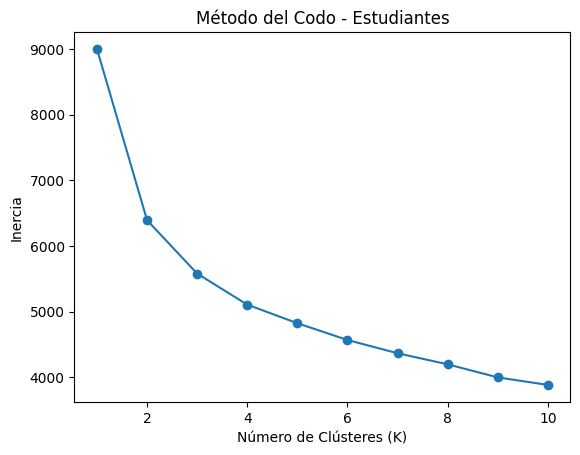

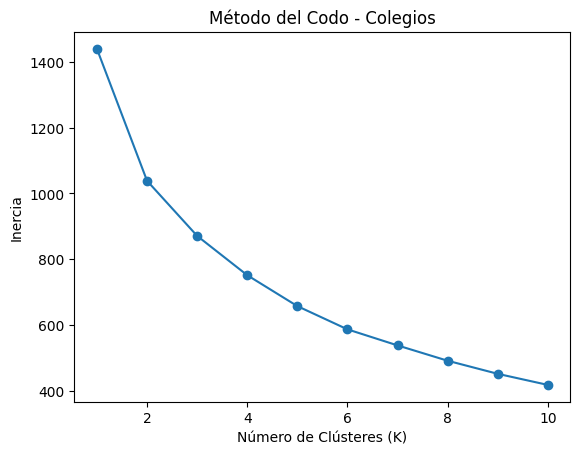

'\nMostramos la gráfica correspondiente al método del codo para los datos de estudiantes y colegios.\nEste permite identificar el número o´timo de clústeres. El valos de k recomendado suele encontrarse \nen el punto donde la disminución de la inercia de de ser significativa, formando una especie de "codo" en la gráfica.\n'

In [8]:
"""
Generamos una gráfica de líneas utilizando los valores de inercia que calculamos para cada número de clústeres (K).DS_Store
En el eje X se representan los valores de K (de 1 a 10) y en el eje Y, la inercia correspondiente a cada modelo.
"""
# Estudiantes
plt.plot(range(1, 11), inercias_estudiantes, marker='o')
plt.title('Método del Codo - Estudiantes')
plt.xlabel('Número de Clústeres (K)')
plt.ylabel('Inercia')
plt.show()

# Colegios
plt.plot(range(1, 11), inercias_colegios, marker='o')
plt.title('Método del Codo - Colegios')
plt.xlabel('Número de Clústeres (K)')
plt.ylabel('Inercia')
plt.show()

"""
Mostramos la gráfica correspondiente al método del codo para los datos de estudiantes y colegios.
Este permite identificar el número o´timo de clústeres. El valos de k recomendado suele encontrarse 
en el punto donde la disminución de la inercia de de ser significativa, formando una especie de "codo" en la gráfica.
"""


In [9]:
"""
Creamos un modelo K-means para agrupar los estudiantes y colegios.

n_clusters=##
    Indica que el algoritmo formará tres clústeres. Este valor suele seleccionarse
    a partir del método del codo, donde se identifica el número de grupos que mejor 
    representa la estructura de los datos.

random_state=42
    Fija la semilla del generador de números aleatorios para que la inicialización de
    los centroidessea siempre la misma. Esto permite obtener resultados reproducibles
    cada vez que se ejecuta el código.

n_init=10
    Ejecuta el algoritmo diez veces utilizando diferentes centroide iniciales y conserva
    la solución con la menosr inercia. Esto reduce la probabilidad de obtener una solución
    de baja calidad debido a una inicialización desfavorable.

"""
km_estudiantes = KMeans(n_clusters=3, random_state=42, n_init=10)
km_colegios = KMeans(n_clusters=4, random_state=42, n_init=10)

In [10]:
"""
Entrenaremos el modelo K-means utilizando el conjunto de datos estandarizado de estudiantes y colegios. 
Y asignamos cada observación al clúster más cercano.

El método fit_predict() realiza dos tareasen una sola instrucción:
    1. fit():
        Entrena el modelo, calculando la posición de losd centroides
        que minimizan la distancia entre las observaciones y el centroide
        de su clúster.
    2. predict():
        Una vez entrenado el modelo, determina a qué clpuster pertenece
        cada observación del conjunto de datos.

El resultado es un arrreglo donde cada elemento corresponde al número del clúster asignado a una observación.
Dicho arreglo se almacena en la variable labels_estudiantes y labels_colegios.
"""
label_estudiantes = km_estudiantes.fit_predict(estudiantes_scaled)
label_colegios = km_colegios.fit_predict(colegios_scaled)


In [11]:
# Agregamos una nueva clumna llamada cluster al Datframe
"""
Cada fila recibe la etiqueta del clúster al que fue asignada por
el algoritmo K-means. De esta manera, cada estudiante y colegio 
queda asociado a uno de los grupos descubiertos automaticamente.
"""
estudiantes['cluster'] = label_estudiantes
colegios_km['cluster'] = label_colegios

# Agrupamos a los estudiantes según el clúster al que pertenece y calculamos el valor promedio de cada variable dentro de cada grupo.
# Este resumen permite identificar el perfil de los estudiantes y colegios que lo conforman

print("\nPromedio de variables por clúster - Estudiantes:")
print(estudiantes.groupby('cluster').mean())
print("\nPromedio de variables por clúster - Colegios:")
print(colegios_km.groupby('cluster').mean())


Promedio de variables por clúster - Estudiantes:
          promedio  materias_reprobadas  carga_academica  asistencia  \
cluster                                                                
0        80.647307             2.854801        29.665105   81.852693   
1        69.538019             4.447284        29.635783   67.754313   
2        92.117308             1.473077        30.046154   90.602692   

         horas_estudio  trabajo_estudiantil      beca  distancia  semestre  
cluster                                                                     
0            15.844262             0.543326  0.000000  26.277986  6.871194  
1             9.106070             0.463259  0.000000  24.734185  6.734824  
2            21.708462             0.469231  0.880769  25.242692  6.850000  

Promedio de variables por clúster - Colegios:
         Val MOVS   Val MAT   Val CRP   Val SOL   Val M/U
cluster                                                  
0       -1.187500 -1.375000  4.031250  4.

/var/folders/3v/_gvrcvhd19x149rwllcc5jsh0000gn/T/ipykernel_31497/2790455240.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  colegios_km['cluster'] = label_colegios


In [12]:
"""
Aplicamos el análisi de componentes principales (PCA) para reducir la dimensionalidad de los datos.

n_components=2
    Indica que los datos originales, que contienen varias variables, serán
    transformados en dos componentes principales. Esto permite representar
    cada estudiante en un plano bidimensional.

fit_transform()
    Primero calcula las dos principales que conservan la mayor cantidad posble
    de información del conjunto de datos y posteriormente, transforma las observaciones
    a ese nuevo espacio.

El resultado se almacena en la variable Z, donde:
- Z[:, 0] corresponde a los valores de la primer componente principal.
- Z[:, 1] corresponde a los valores de la segundo componente principal.

Es importante destacar que PCA no froma los clúster; únicamente reduce la dimensionalidad
para facilitar la visualización de los grupos encontrados previamente por K-Means.
"""

z_estudiantes = PCA(n_components=2).fit_transform(estudiantes_scaled)
z_colegios = PCA(n_components=2).fit_transform(colegios_scaled)

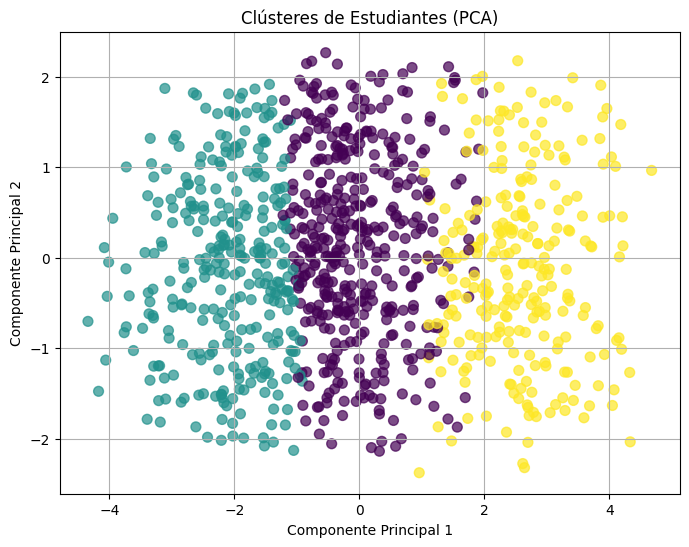

In [13]:
# Generamos un diagrama de dispersión de los dos componentes principales.
plt.figure(figsize=(8, 6))
plt.scatter(z_estudiantes[:, 0], z_estudiantes[:, 1], c=label_estudiantes, s=50, alpha=0.7)
# Agregamos etiquetas y título al gráfico
plt.title('Clústeres de Estudiantes (PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

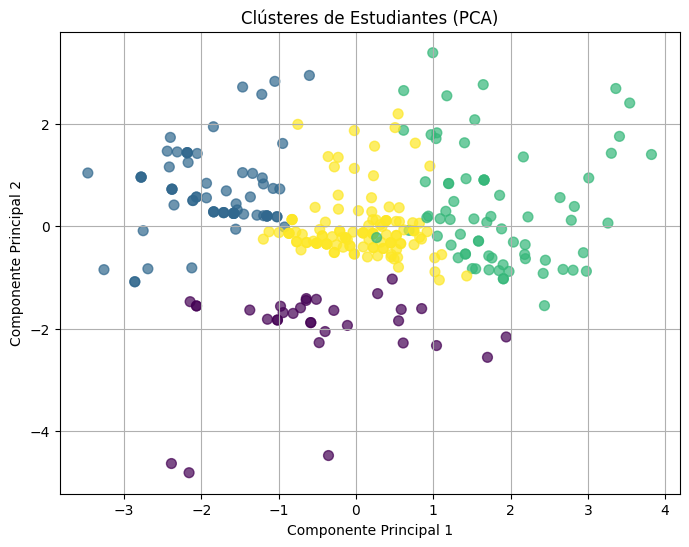

In [14]:
# Generamos un diagrama de dispersión de los dos componentes principales.
plt.figure(figsize=(8, 6))
plt.scatter(z_colegios[:, 0], z_colegios[:, 1], c=label_colegios, s=50, alpha=0.7)
# Agregamos etiquetas y título al gráfico
plt.title('Clústeres de Estudiantes (PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

Silhouette Score para k=2: 0.2527
Silhouette Score para k=3: 0.2292
Silhouette Score para k=4: 0.2519
Silhouette Score para k=5: 0.2709
Silhouette Score para k=6: 0.2842
Silhouette Score para k=7: 0.2527
Silhouette Score para k=8: 0.2678
Silhouette Score para k=9: 0.2737
Silhouette Score para k=10: 0.2907


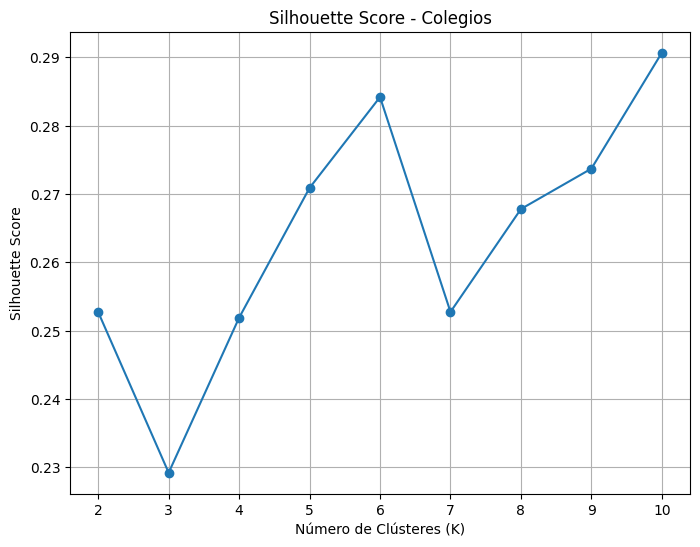

In [ ]:
# Evaluar el SILHOUETTE SCORE para los COLEGIOS y ver si hicimos una elección correcta
valores_silhouette_colegios = range(2, 11)
silhouette_scores_colegios = []

for k in valores_silhouette_colegios:
    modelo_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = modelo_kmeans.fit_predict(colegios_scaled)
    score = silhouette_score(colegios_scaled, labels)
    silhouette_scores_colegios.append(score)
    print(f"Silhouette Score para k={k}: {score:.4f}")

#Grafica
plt.figure(figsize=(8, 6))
plt.plot(valores_silhouette_colegios, silhouette_scores_colegios, marker='o')
plt.title('Silhouette Score - Colegios')
plt.xlabel('Número de Clústeres (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(valores_silhouette_colegios))
plt.grid(True)
plt.show()